### WELCOME TO PHASE 2:I USED THE PYTHAN TOOL LIKE LIBRARIES,MISSING VALUE ANALYSIS,OUTLIER,CATEGORICAL TO NUMERICAL,INPUT VALIDATION FOR MY PROJECT.

* **Project Objective:** To analyze clinical parameters, vitals, and anesthesia dosages to minimize PACU recovery time and enhance patient outcomes using advanced data science workflows.
* **Workflow Steps:** Data Loading -> Missing Value Treatment -> Outlier Capping -> Categorical Encoding -> Input Validation -> Clinical Impact Visualizations.

### STEP 1:IMPORT LIBRARIES & LOAD DATASET:

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

In [17]:
df = pd.read_csv('Downloads/clinical_anesthesia_dataset.csv')

# 1. To Explore The Dataset:

In [128]:
df.head(5)

,Patient_ID,Age,Weight_kg,Height_cm,BMI,NPO_Fasting_Hours,PreOp_HR,PreOp_SBP,PreOp_DBP,PreOp_SpO2,...,Surgery_Type_Lap_Cholecystectomy,Surgery_Type_Ortho_Lower_Limb,Surgery_Type_Wound_Debridement,Anesthesia_Type_General,Anesthesia_Type_Local,Anesthesia_Type_Spinal,Surgical_Site_Lower_Abdomen,Surgical_Site_Lower_Limb,Surgical_Site_Upper_Abdomen,Surgical_Site_Upper_Limb
0,PT_0001,49,61.3,164.5,22.7,6,69,115,72,99,...,0,0,0,1,0,0,1,0,0,0
1,PT_0002,37,83.5,168.3,29.5,10,99,140,78,96,...,0,0,0,1,0,0,1,0,0,0
2,PT_0003,41,83.5,159.4,32.9,6,62,120,90,99,...,0,0,0,0,0,1,1,0,0,0
3,PT_0004,64,67.6,177.2,21.5,6,81,160,85,96,...,0,1,0,1,0,0,0,1,0,0
4,PT_0005,65,46.0,157.3,18.6,10,93,126,68,96,...,0,0,0,1,0,0,0,0,0,0


In [129]:
df.tail(5)

,Patient_ID,Age,Weight_kg,Height_cm,BMI,NPO_Fasting_Hours,PreOp_HR,PreOp_SBP,PreOp_DBP,PreOp_SpO2,...,Surgery_Type_Lap_Cholecystectomy,Surgery_Type_Ortho_Lower_Limb,Surgery_Type_Wound_Debridement,Anesthesia_Type_General,Anesthesia_Type_Local,Anesthesia_Type_Spinal,Surgical_Site_Lower_Abdomen,Surgical_Site_Lower_Limb,Surgical_Site_Upper_Abdomen,Surgical_Site_Upper_Limb
1005,PT_0006,39,61.1,160.9,23.6,10,85,104,80,97,...,0,0,0,1,0,0,1,0,0,0
1006,PT_0007,55,71.8,168.9,25.2,6,97,159,67,97,...,0,0,0,1,0,0,1,0,0,0
1007,PT_0008,77,68.2,168.4,24.0,8,69,161,66,98,...,0,0,1,0,0,1,0,0,0,1
1008,PT_0009,78,66.0,167.6,14.6,8,81,128,78,95,...,0,0,0,1,0,0,0,0,0,0
1009,PT_0010,75,59.3,166.6,21.4,8,65,147,91,99,...,0,0,0,1,0,0,1,0,0,0


In [22]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Weight_kg', 'Height_cm', 'BMI',
       'NPO_Fasting_Hours', 'PreOp_HR', 'PreOp_SBP', 'PreOp_DBP', 'PreOp_SpO2',
       'ASA_Grade', 'Mallampati_Score', 'Comorbidities',
       'Previous_Surgeries_Count', 'Prev_Anesthesia_Complication',
       'Hemoglobin_g_dL', 'Serum_Creatinine', 'Habits_History', 'Surgery_Type',
       'Surgical_Site', 'Urgency_Level', 'OR_Entry_Time', 'OR_Exit_Time',
       'Actual_OT_Duration_mins', 'Anesthesia_Type', 'Premed_Anticholinergic',
       'Glycopyrrolate_Dose_mg', 'Premed_Sedative', 'Midazolam_Dose_mg',
       'Spinal_Local_Drug', 'Bupivacaine_Dose_mg',
       'Spinal_Adjuvant_Fentanyl_mcg', 'GA_Induction_Agent',
       'Induction_Dose_mg', 'IntraOp_Analgesic', 'Analgesic_Dose_mcg',
       'Relaxant_Category', 'Muscle_Relaxant_Drug', 'Relaxant_Dose_mg',
       'Reversal_Agent', 'Reversal_Dose_mg', 'IntraOp_Hypotension_Event',
       'IntraOp_Min_MAP_mmHg', 'Rescue_Vasopressor_Used',
       'Extubation_Time_mins', '

In [23]:
df.info

<bound method DataFrame.info of      Patient_ID  Age  Gender  Weight_kg  Height_cm   BMI  NPO_Fasting_Hours  \
0       PT_0001   49  Female       61.3      164.5  22.7                  6   
1       PT_0002   37  Female       83.5      168.3  29.5                 10   
2       PT_0003   41    Male       83.5      159.4  32.9                  6   
3       PT_0004   64  Female       67.6      177.2  21.5                  6   
4       PT_0005   65    Male       46.0      157.3  18.6                 10   
...         ...  ...     ...        ...        ...   ...                ...   
1005    PT_0006   39    Male       61.1      160.9  23.6                 10   
1006    PT_0007   55  Female       71.8      168.9  25.2                  6   
1007    PT_0008   77    Male       68.2      168.4  24.0                  8   
1008    PT_0009   78    Male        NaN      167.6  14.6                  8   
1009    PT_0010   75  Female       59.3      166.6  21.4                  8   

      PreOp_HR  Pre

In [24]:
df.describe()

,Age,Weight_kg,Height_cm,BMI,NPO_Fasting_Hours,PreOp_HR,PreOp_SBP,PreOp_DBP,PreOp_SpO2,Previous_Surgeries_Count,...,Spinal_Adjuvant_Fentanyl_mcg,Induction_Dose_mg,Analgesic_Dose_mcg,Relaxant_Dose_mg,Reversal_Dose_mg,IntraOp_Min_MAP_mmHg,Extubation_Time_mins,PACU_Recovery_Time_mins,Aldrete_Score_Discharge,PostOp_Pain_Score_VAS
count,1010.000000,979.000000,1010.000000,1010.000000,1010.000000,1010.000000,1010.000000,1010.000000,1010.000000,1010.000000,...,1010.000000,1010.000000,1010.000000,1010.000000,1010.000000,997.000000,1010.000000,985.000000,1010.000000,1010.000000
mean,49.511881,66.924617,164.157525,24.628515,8.752475,80.479208,131.716832,79.772277,96.995050,1.524752,...,4.410891,61.437822,397.708416,13.248614,5.608317,75.024072,7.402079,41.385990,9.237624,4.406931
std,17.673068,19.305153,7.945915,4.923057,2.221643,11.913467,17.232308,9.341003,1.391955,1.114763,...,8.354419,63.098064,424.748183,14.614204,5.851156,11.077376,5.862207,16.460376,0.691854,1.858671
min,18.000000,33.900000,134.200000,12.600000,4.000000,60.000000,102.000000,64.000000,95.000000,0.000000,...,0.000000,0.000000,50.800000,0.000000,0.000000,52.000000,0.000000,11.700000,8.000000,1.000000
25%,34.000000,57.900000,158.800000,21.200000,8.000000,70.250000,116.000000,72.000000,96.000000,1.000000,...,0.000000,0.000000,92.725000,0.000000,0.000000,69.000000,0.000000,31.600000,9.000000,3.000000
50%,50.000000,66.000000,164.200000,24.300000,10.000000,81.000000,132.000000,80.000000,97.000000,2.000000,...,0.000000,22.100000,111.200000,6.600000,3.300000,76.000000,8.800000,40.600000,9.000000,4.000000
75%,65.000000,74.000000,169.400000,27.900000,10.000000,90.000000,147.000000,88.000000,98.000000,3.000000,...,0.000000,125.550000,1000.000000,28.875000,11.800000,84.000000,12.100000,49.100000,10.000000,6.000000
max,79.000000,310.000000,190.200000,43.700000,12.000000,101.000000,161.000000,95.000000,99.000000,3.000000,...,25.000000,198.000000,1000.000000,47.200000,19.800000,91.000000,20.900000,195.000000,10.000000,7.000000


In [25]:
df.shape

(1010, 51)

In [124]:
df.drop_duplicates().shape

(1000, 62)

In [28]:
df_sampled = df.sample(n=50, random_state=42)
df_sampled.head()

,Patient_ID,Age,Gender,Weight_kg,Height_cm,BMI,NPO_Fasting_Hours,PreOp_HR,PreOp_SBP,PreOp_DBP,...,Reversal_Dose_mg,IntraOp_Hypotension_Event,IntraOp_Min_MAP_mmHg,Rescue_Vasopressor_Used,Extubation_Time_mins,PACU_Recovery_Time_mins,Aldrete_Score_Discharge,PostOp_Pain_Score_VAS,PONV_Occurred,Adverse_Event_CTCAE_Grade
629,PT_0630,40,Female,73.3,165.9,26.6,12,77,131,75,...,0.0,Yes,52.0,Ephedrine,0.0,31.8,10,1,No,Grade 1
788,PT_0789,60,Male,54.1,160.4,21.0,10,99,122,78,...,10.8,No,78.0,NaN,12.4,38.7,10,5,No,Grade 0
684,PT_0685,62,Female,51.9,150.8,22.8,6,66,150,68,...,10.4,No,87.0,NaN,8.9,37.2,9,3,Yes,Grade 1
516,PT_0517,71,Female,62.4,154.0,26.3,8,94,123,79,...,0.0,No,84.0,NaN,0.0,30.0,9,3,No,Grade 0
529,PT_0530,72,Male,81.9,152.4,35.3,10,60,102,88,...,16.4,Yes,60.0,Phenylephrine,10.3,52.2,9,5,No,Grade 3


In [125]:
df.shape

(1010, 62)

### STEP 2: DATE-TIME & STRING MANIPULATION:Step 2:

In [30]:
import pandas as pd
import numpy as np

# 1. DATETIME MANIPILATION:

In [34]:
df['OR_Entry_Time'] = pd.to_datetime(df['OR_Entry_Time'])
df['OR_Exit_Time'] = pd.to_datetime(df['OR_Exit_Time'])
df['Calculated_OT_Duration'] = (
    df['OR_Exit_Time'] - df['OR_Entry_Time']
).dt.total_seconds() / 60

In [35]:
df[['OR_Entry_Time', 'OR_Exit_Time', 'Calculated_OT_Duration']].head()

,OR_Entry_Time,OR_Exit_Time,Calculated_OT_Duration
0,2026-11-16 11:34:00,2026-11-16 12:48:00,74.0
1,2026-11-16 15:19:00,2026-11-16 18:32:00,193.0
2,2026-11-16 11:06:00,2026-11-16 13:19:00,133.0
3,2026-11-16 11:56:00,2026-11-16 14:33:00,157.0
4,2026-11-16 14:07:00,2026-11-16 16:01:00,114.0


 # 2. STRING MANIPULATION:

In [36]:
df['Comorbidities'] = df['Comorbidities'].str.strip().str.title()

In [38]:
df['Comorbidities'].head()

0    Hypertension
1         Cardiac
2        Diabetes
3         Cardiac
4             NaN
Name: Comorbidities, dtype: str

# 3. FINAL ANALYSIS:

In [107]:
df.head(10)

,Patient_ID,Age,Weight_kg,Height_cm,BMI,NPO_Fasting_Hours,PreOp_HR,PreOp_SBP,PreOp_DBP,PreOp_SpO2,...,Surgery_Type_Lap_Cholecystectomy,Surgery_Type_Ortho_Lower_Limb,Surgery_Type_Wound_Debridement,Anesthesia_Type_General,Anesthesia_Type_Local,Anesthesia_Type_Spinal,Surgical_Site_Lower_Abdomen,Surgical_Site_Lower_Limb,Surgical_Site_Upper_Abdomen,Surgical_Site_Upper_Limb
0,PT_0001,49,61.3,164.5,22.7,6,69,115,72,99,...,0,0,0,1,0,0,1,0,0,0
1,PT_0002,37,83.5,168.3,29.5,10,99,140,78,96,...,0,0,0,1,0,0,1,0,0,0
2,PT_0003,41,83.5,159.4,32.9,6,62,120,90,99,...,0,0,0,0,0,1,1,0,0,0
3,PT_0004,64,67.6,177.2,21.5,6,81,160,85,96,...,0,1,0,1,0,0,0,1,0,0
4,PT_0005,65,46.0,157.3,18.6,10,93,126,68,96,...,0,0,0,1,0,0,0,0,0,0
5,PT_0006,39,61.1,160.9,23.6,10,85,104,80,97,...,0,0,0,1,0,0,1,0,0,0
6,PT_0007,55,71.8,168.9,25.2,6,97,159,67,97,...,0,0,0,1,0,0,1,0,0,0
7,PT_0008,77,68.2,168.4,24.0,8,69,161,66,98,...,0,0,1,0,0,1,0,0,0,1
8,PT_0009,78,66.0,167.6,14.6,8,81,128,78,95,...,0,0,0,1,0,0,0,0,0,0
9,PT_0010,75,59.3,166.6,21.4,8,65,147,91,99,...,0,0,0,1,0,0,1,0,0,0


# 4. DATETIME MANIPULATION VISUALIZATION:

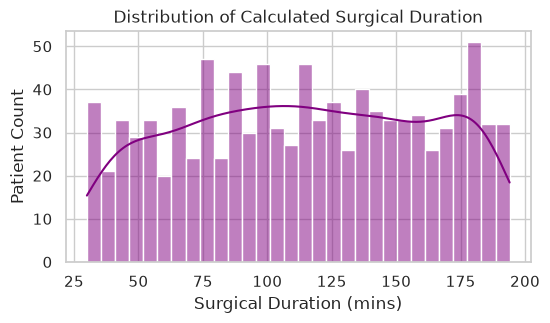

In [138]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 3))
sns.histplot(df['Calculated_OT_Duration'].dropna(), bins=30, color='purple', kde=True)
plt.title('Distribution of Calculated Surgical Duration')
plt.xlabel('Surgical Duration (mins)')
plt.ylabel('Patient Count')
plt.show()

### STEP 3: MISSING VALUE TREATMENT:

# 1. CHECKING DUPLICATES & MISSING VALUES:

In [44]:
df.isnull().sum()1: Anesthesia Type vs PACU Recovery Time1: Anesthesia Type vs PACU Recovery Time

Patient_ID                        0
Age                               0
Gender                            0
Weight_kg                        31
Height_cm                         0
BMI                               0
NPO_Fasting_Hours                 0
PreOp_HR                          0
PreOp_SBP                         0
PreOp_DBP                         0
PreOp_SpO2                        0
ASA_Grade                         0
Mallampati_Score                  0
Comorbidities                   413
Previous_Surgeries_Count          0
Prev_Anesthesia_Complication      0
Hemoglobin_g_dL                  18
Serum_Creatinine                  0
Habits_History                  557
Surgery_Type                      0
Surgical_Site                     0
Urgency_Level                     0
OR_Entry_Time                     0
OR_Exit_Time                      0
Actual_OT_Duration_mins           0
Anesthesia_Type                   0
Premed_Anticholinergic           21
Glycopyrrolate_Dose_mg      

In [49]:
df.duplicated().sum()

np.int64(10)

# 2. IMPUTING MISSING DRUG DATA WITH NOT APLLICABLE:

In [50]:
df['Spinal_Local_Drug'] = df['Spinal_Local_Drug'].fillna('Not_Applicable')
df['GA_Induction_Agent'] = df['GA_Induction_Agent'].fillna('Not_Applicable')
df['Relaxant_Category'] = df['Relaxant_Category'].fillna('Not_Applicable')
df['Muscle_Relaxant_Drug'] = df['Muscle_Relaxant_Drug'].fillna('Not_Applicable')
df['Reversal_Agent'] = df['Reversal_Agent'].fillna('Not_Applicable')
df['Premed_Anticholinergic'] = df['Premed_Anticholinergic'].fillna('Not_Applicable')

# 3. HANDLING CLINICAL ABSENCE & HABITS:

In [51]:
df['Comorbidities'] = df['Comorbidities'].fillna('No_Comorbidities')
df['Habits_History'] = df['Habits_History'].fillna('No_Habits')
df['Rescue_Vasopressor_Used'] = df['Rescue_Vasopressor_Used'].fillna('No')

# 4. MEDIAN IMPUTATION FOR VITALS & LAB VALUES:

In [54]:
df['Weight_kg'] = df['Weight_kg'].fillna(df['Weight_kg'].median())
df['Hemoglobin_g_dL'] = df['Hemoglobin_g_dL'].fillna(
df['Hemoglobin_g_dL'].median())

# 5. FINAL ANALYSIS:

In [56]:
df.head(10)

,Patient_ID,Age,Gender,Weight_kg,Height_cm,BMI,NPO_Fasting_Hours,PreOp_HR,PreOp_SBP,PreOp_DBP,...,IntraOp_Hypotension_Event,IntraOp_Min_MAP_mmHg,Rescue_Vasopressor_Used,Extubation_Time_mins,PACU_Recovery_Time_mins,Aldrete_Score_Discharge,PostOp_Pain_Score_VAS,PONV_Occurred,Adverse_Event_CTCAE_Grade,Calculated_OT_Duration
0,PT_0001,49,Female,61.3,164.5,22.7,6,69,115,72,...,No,77.0,No,12.5,54.1,9,4,Yes,Grade 2,74.0
1,PT_0002,37,Female,83.5,168.3,29.5,10,99,140,78,...,No,NaN,No,12.1,52.4,10,5,No,Grade 0,193.0
2,PT_0003,41,Male,83.5,159.4,32.9,6,62,120,90,...,No,70.0,No,0.0,33.7,9,3,No,Grade 0,133.0
3,PT_0004,64,Female,67.6,177.2,21.5,6,81,160,85,...,No,85.0,No,9.1,30.5,9,3,Yes,Grade 2,157.0
4,PT_0005,65,Male,46.0,157.3,18.6,10,93,126,68,...,No,75.0,No,9.0,38.7,9,4,No,Grade 0,114.0
5,PT_0006,39,Male,61.1,160.9,23.6,10,85,104,80,...,Yes,63.0,Ephedrine,12.3,55.2,9,4,No,Grade 1,138.0
6,PT_0007,55,Female,71.8,168.9,25.2,6,97,159,67,...,No,75.0,No,7.9,36.1,10,6,No,Grade 0,175.0
7,PT_0008,77,Male,68.2,168.4,24.0,8,69,161,66,...,No,74.0,No,0.0,32.2,9,3,No,Grade 0,55.0
8,PT_0009,78,Male,66.0,167.6,14.6,8,81,128,78,...,No,80.0,No,12.2,42.6,9,4,Yes,Grade 2,71.0
9,PT_0010,75,Female,59.3,166.6,21.4,8,65,147,91,...,No,84.0,No,6.4,37.8,10,4,No,Grade 0,152.0


# 6. MISSING VALUE VISUALIZATION:

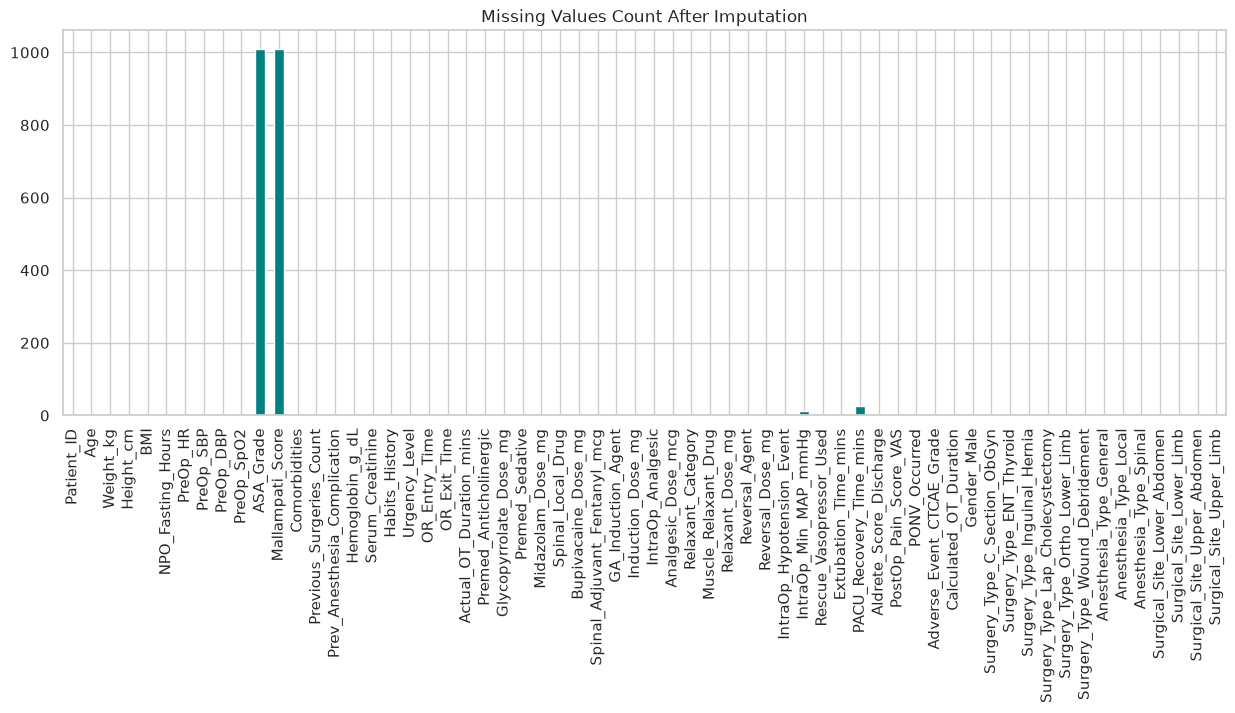

In [135]:
plt.figure(figsize=(15, 5))
df.isnull().sum().plot(kind='bar', color='teal')
plt.title('Missing Values Count After Imputation')
plt.xticks(rotation=90)
plt.show()

### Step 4: Outlier Treatment using IQR Method:

# 1. Selecting Columns for Outlier Analysis:

In [59]:
df_outlier_cols = ['BMI','Weight_kg','Hemoglobin_g_dL','Calculated_OT_Duration',]

# 2. Applying IQR Formula and Capping Outliers:

In [60]:
for df_col in df_outlier_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
  df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

# 3. Final Analysis:

In [61]:
df.head(10)

,Patient_ID,Age,Gender,Weight_kg,Height_cm,BMI,NPO_Fasting_Hours,PreOp_HR,PreOp_SBP,PreOp_DBP,...,IntraOp_Hypotension_Event,IntraOp_Min_MAP_mmHg,Rescue_Vasopressor_Used,Extubation_Time_mins,PACU_Recovery_Time_mins,Aldrete_Score_Discharge,PostOp_Pain_Score_VAS,PONV_Occurred,Adverse_Event_CTCAE_Grade,Calculated_OT_Duration
0,PT_0001,49,Female,61.3,164.5,22.7,6,69,115,72,...,No,77.0,No,12.5,54.1,9,4,Yes,Grade 2,74.0
1,PT_0002,37,Female,83.5,168.3,29.5,10,99,140,78,...,No,NaN,No,12.1,52.4,10,5,No,Grade 0,193.0
2,PT_0003,41,Male,83.5,159.4,32.9,6,62,120,90,...,No,70.0,No,0.0,33.7,9,3,No,Grade 0,133.0
3,PT_0004,64,Female,67.6,177.2,21.5,6,81,160,85,...,No,85.0,No,9.1,30.5,9,3,Yes,Grade 2,157.0
4,PT_0005,65,Male,46.0,157.3,18.6,10,93,126,68,...,No,75.0,No,9.0,38.7,9,4,No,Grade 0,114.0
5,PT_0006,39,Male,61.1,160.9,23.6,10,85,104,80,...,Yes,63.0,Ephedrine,12.3,55.2,9,4,No,Grade 1,138.0
6,PT_0007,55,Female,71.8,168.9,25.2,6,97,159,67,...,No,75.0,No,7.9,36.1,10,6,No,Grade 0,175.0
7,PT_0008,77,Male,68.2,168.4,24.0,8,69,161,66,...,No,74.0,No,0.0,32.2,9,3,No,Grade 0,55.0
8,PT_0009,78,Male,66.0,167.6,14.6,8,81,128,78,...,No,80.0,No,12.2,42.6,9,4,Yes,Grade 2,71.0
9,PT_0010,75,Female,59.3,166.6,21.4,8,65,147,91,...,No,84.0,No,6.4,37.8,10,4,No,Grade 0,152.0


# 4. OUTLIER VISUALIZATION:

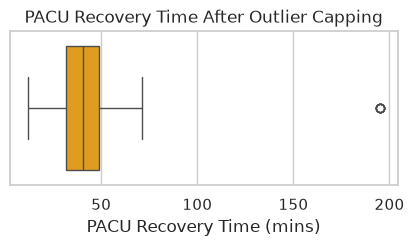

In [136]:
plt.figure(figsize=(5, 2))
sns.boxplot(x=df['PACU_Recovery_Time_mins'], color='orange')
plt.title('PACU Recovery Time After Outlier Capping')
plt.xlabel('PACU Recovery Time (mins)')
plt.show()

### Step 5: Categorical to Numerical Data Conversion:

# 1. Ordinal Encoding for ASA Grades and Mallampati Scores:

In [69]:
df['ASA_Grade'] = df['ASA_Grade'].map({
    'Grade_I': 1,
    'Grade_II': 2,
    'Grade_III': 3,
    'Grade_IV': 4,
})

df['Mallampati_Score'] = df['Mallampati_Score'].map({
    'Class_I': 1,
    'Class_II': 2,
    'Class_III': 3,
    'Class_IV': 4,
})

# 3. Creating Dummy Variables for Nominal Data:

In [73]:
df = pd.get_dummies(df, columns=['Gender'], drop_first=True, dtype=int)

In [74]:
df = pd.get_dummies(df, columns=['Surgery_Type'], drop_first=True, dtype=int)

In [76]:
df = pd.get_dummies(df, columns=['Anesthesia_Type'], drop_first=True, dtype=int)

In [77]:
df = pd.get_dummies(df, columns=['Surgical_Site'], drop_first=True, dtype=int)

# 4. Final Analysis:

In [78]:
df.head(10)

,Patient_ID,Age,Weight_kg,Height_cm,BMI,NPO_Fasting_Hours,PreOp_HR,PreOp_SBP,PreOp_DBP,PreOp_SpO2,...,Surgery_Type_Lap_Cholecystectomy,Surgery_Type_Ortho_Lower_Limb,Surgery_Type_Wound_Debridement,Anesthesia_Type_General,Anesthesia_Type_Local,Anesthesia_Type_Spinal,Surgical_Site_Lower_Abdomen,Surgical_Site_Lower_Limb,Surgical_Site_Upper_Abdomen,Surgical_Site_Upper_Limb
0,PT_0001,49,61.3,164.5,22.7,6,69,115,72,99,...,0,0,0,1,0,0,1,0,0,0
1,PT_0002,37,83.5,168.3,29.5,10,99,140,78,96,...,0,0,0,1,0,0,1,0,0,0
2,PT_0003,41,83.5,159.4,32.9,6,62,120,90,99,...,0,0,0,0,0,1,1,0,0,0
3,PT_0004,64,67.6,177.2,21.5,6,81,160,85,96,...,0,1,0,1,0,0,0,1,0,0
4,PT_0005,65,46.0,157.3,18.6,10,93,126,68,96,...,0,0,0,1,0,0,0,0,0,0
5,PT_0006,39,61.1,160.9,23.6,10,85,104,80,97,...,0,0,0,1,0,0,1,0,0,0
6,PT_0007,55,71.8,168.9,25.2,6,97,159,67,97,...,0,0,0,1,0,0,1,0,0,0
7,PT_0008,77,68.2,168.4,24.0,8,69,161,66,98,...,0,0,1,0,0,1,0,0,0,1
8,PT_0009,78,66.0,167.6,14.6,8,81,128,78,95,...,0,0,0,1,0,0,0,0,0,0
9,PT_0010,75,59.3,166.6,21.4,8,65,147,91,99,...,0,0,0,1,0,0,1,0,0,0


# 5.NUMERICAL DATA VISUALIZATION:

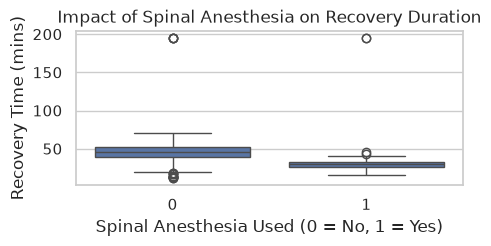

In [137]:
plt.figure(figsize=(5, 2))
sns.boxplot(
    data=df,
    x=df['Anesthesia_Type_Spinal'].astype(str),
    y='PACU_Recovery_Time_mins',
)
plt.title('Impact of Spinal Anesthesia on Recovery Duration')
plt.xlabel('Spinal Anesthesia Used (0 = No, 1 = Yes)')
plt.ylabel('Recovery Time (mins)')
plt.show()

### Step 6: Input Validation and Range Verification:

# 1. TO CHECK RANGE:

In [83]:
df['Age'].between(0, 120).all()
df['PreOp_SpO2'].between(70, 100).all()

np.True_

# 2. To Handle The MIssing Values:

In [92]:
df.isnull().sum()

Patient_ID                     0
Age                            0
Weight_kg                      0
Height_cm                      0
BMI                            0
                              ..
Anesthesia_Type_Spinal         0
Surgical_Site_Lower_Abdomen    0
Surgical_Site_Lower_Limb       0
Surgical_Site_Upper_Abdomen    0
Surgical_Site_Upper_Limb       0
Length: 62, dtype: int64

# 3. INPUT VALIDATION PROCESS:

In [98]:
assert df['Age'].between(0, 120).all(), "Age values are out of range!"
assert df['PreOp_SpO2'].between(70, 100).all(), "SpO2 values are out of range!"

print("Input Validation Passed Successfully: Data is clean and ready for ML modeling!")

Input Validation Passed Successfully: Data is clean and ready for ML modeling!


### STEP7: FINAL CLINICAL IMPACT VISUALIZATION:

In [108]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. ANESTHESIA TYPE VS PACU RECOVERY TIME:

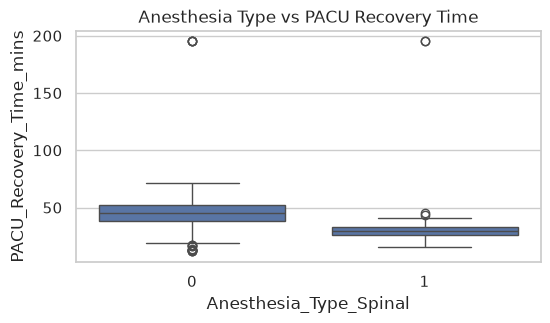

In [116]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 3))
sns.boxplot(
    data=df,
    x=df['Anesthesia_Type_Spinal'].astype(str),
    y='PACU_Recovery_Time_mins',
)
plt.title('Anesthesia Type vs PACU Recovery Time')
plt.show()

# 2. ASA GRADE VS RECOVERY TIME:

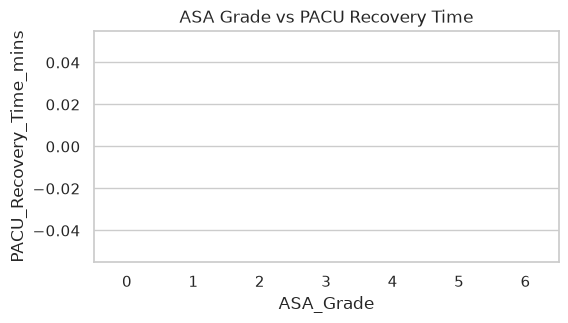

In [117]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6, 3))
sns.barplot(
    data=df, x=df['ASA_Grade'].astype(str), y='PACU_Recovery_Time_mins'
)
plt.title('ASA Grade vs PACU Recovery Time')
plt.show()

# 3. PATIENT AGE DISTRIBUTION:

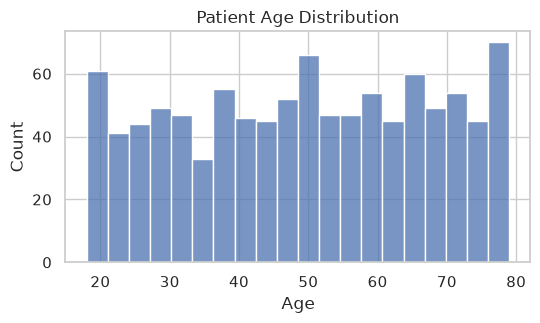

In [118]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6, 3))
sns.histplot(df['Age'], bins=20)
plt.title('Patient Age Distribution')
plt.show()

# 4. PREOP SPO2 VS PACU RECOVERY TIME:

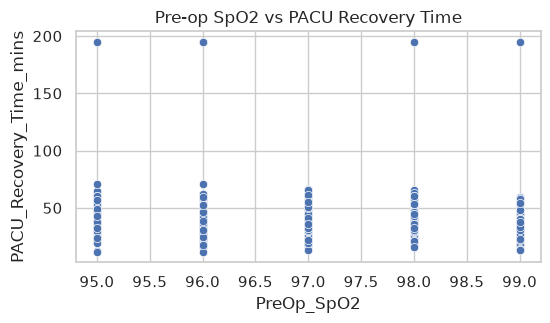

In [119]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6, 3))
sns.scatterplot(data=df, x='PreOp_SpO2', y='PACU_Recovery_Time_mins')
plt.title('Pre-op SpO2 vs PACU Recovery Time')
plt.show()

# 5. BUPIVACAINE DOSAGE VS PACU RECOVERY TIME:

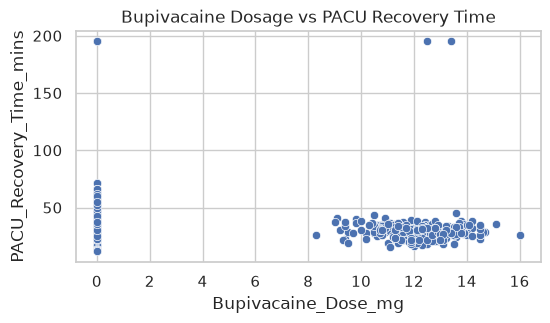

In [120]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6, 3))
sns.scatterplot(data=df, x='Bupivacaine_Dose_mg', y='PACU_Recovery_Time_mins')
plt.title('Bupivacaine Dosage vs PACU Recovery Time')
plt.show()

# 6. PATIENT BMI VS PACU RECOVERY TIME:

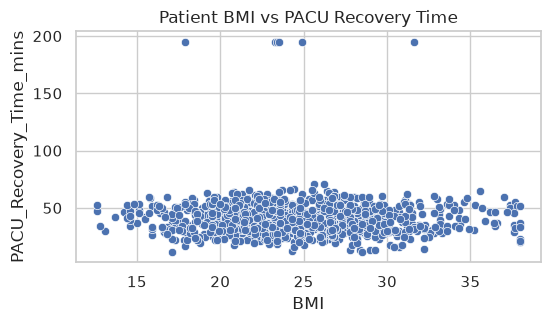

In [121]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6, 3))
sns.scatterplot(data=df, x='BMI', y='PACU_Recovery_Time_mins')
plt.title('Patient BMI vs PACU Recovery Time')
plt.show()

# 7. CLINICAL PARAMETERS CORRELATION MATRIX:

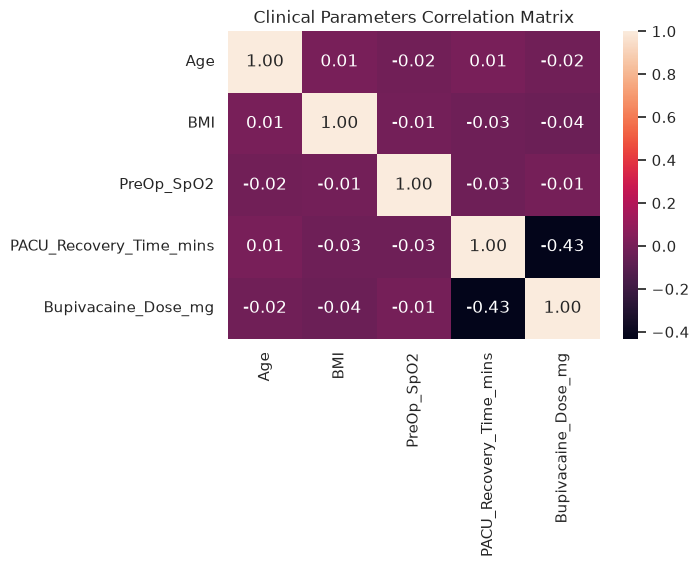

In [122]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6, 4))
sns.heatmap(
    df[[
        'Age',
        'BMI',
        'PreOp_SpO2',
        'PACU_Recovery_Time_mins',
        'Bupivacaine_Dose_mg',
    ]].corr(),
    annot=True,
    fmt='.2f',
)
plt.title('Clinical Parameters Correlation Matrix')
plt.show()

### FINAL ANALYSIS & CLEANED DATASET OVERVIEW
* **PROCESS SUMMARY:** ALL PREPROCESSING STEPS INCLUDING MISSING VALUE IMPUTATION, OUTLIER CAPPING, CATEGORICAL ENCODING, AND INPUT VALIDATION HAVE BEEN SUCCESSFULLY COMPLETED.
* **FINAL RESULT:** THE DATASET IS NOW CLEAN, ROBUST, AND FULLY OPTIMIZED FOR ADVANCED CLINICAL DATA MODELING AND MACHINE LEARNING WORKFLOWS.

In [131]:
print("Final Cleaned Dataset Shape (Rows, Columns):", df.shape)
df.head(5)

Final Cleaned Dataset Shape (Rows, Columns): (1010, 62)


,Patient_ID,Age,Weight_kg,Height_cm,BMI,NPO_Fasting_Hours,PreOp_HR,PreOp_SBP,PreOp_DBP,PreOp_SpO2,...,Surgery_Type_Lap_Cholecystectomy,Surgery_Type_Ortho_Lower_Limb,Surgery_Type_Wound_Debridement,Anesthesia_Type_General,Anesthesia_Type_Local,Anesthesia_Type_Spinal,Surgical_Site_Lower_Abdomen,Surgical_Site_Lower_Limb,Surgical_Site_Upper_Abdomen,Surgical_Site_Upper_Limb
0,PT_0001,49,61.3,164.5,22.7,6,69,115,72,99,...,0,0,0,1,0,0,1,0,0,0
1,PT_0002,37,83.5,168.3,29.5,10,99,140,78,96,...,0,0,0,1,0,0,1,0,0,0
2,PT_0003,41,83.5,159.4,32.9,6,62,120,90,99,...,0,0,0,0,0,1,1,0,0,0
3,PT_0004,64,67.6,177.2,21.5,6,81,160,85,96,...,0,1,0,1,0,0,0,1,0,0
4,PT_0005,65,46.0,157.3,18.6,10,93,126,68,96,...,0,0,0,1,0,0,0,0,0,0
